# Demand forecasting and evaluation

**Author:** Molemi Molokoane (Member 3)

**Question:** How many units of each top 10 product will the shop sell in the coming weeks?

## Step 1: Load the weekly sales and check them

Before using the data, we check that it is complete, the same way you would count a delivery before putting it on the shelves.

We expect 10 products, each with 54 weeks of sales.

In [1]:
# Connect Colab to Google Drive, where the team's data files are kept.
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd

DRIVE_ROOT = '/content/drive/MyDrive/WTM-Data-Science-Group-B'

# StockCode is a label, not a number (some codes contain letters, like 85099B).
weekly_sales = pd.read_csv(
    f'{DRIVE_ROOT}/data/processed/weekly_sales.csv',
    dtype={'StockCode': str},
    parse_dates=['Week'],
)

# Some product names have a stray space at the end.
weekly_sales['Description'] = weekly_sales['Description'].str.strip()

# Put each product's weeks in date order, because forecasting depends on that order.
weekly_sales = weekly_sales.sort_values(['StockCode', 'Week']).reset_index(drop=True)

weekly_sales.head()

,StockCode,Week,Description,WeeklyQuantity
0,21212,2010-11-29,PACK OF 72 RETROSPOT CAKE CASES,975
1,21212,2010-12-06,PACK OF 72 RETROSPOT CAKE CASES,1104
2,21212,2010-12-13,PACK OF 72 RETROSPOT CAKE CASES,664
3,21212,2010-12-20,PACK OF 72 RETROSPOT CAKE CASES,1363
4,21212,2010-12-27,PACK OF 72 RETROSPOT CAKE CASES,0


In [3]:
# Check the file as a whole.
print('Rows:', len(weekly_sales))
print('Products:', weekly_sales['StockCode'].nunique())
print('Weeks:', weekly_sales['Week'].nunique())
print('First week:', weekly_sales['Week'].min().date())
print('Last week:', weekly_sales['Week'].max().date())
print('Total quantity:', weekly_sales['WeeklyQuantity'].sum())
print('Product-weeks at zero:', (weekly_sales['WeeklyQuantity'] == 0).sum())

# Check each product: total sold, and how many weeks it sold nothing.
weekly_sales.groupby(['StockCode', 'Description'])['WeeklyQuantity'].agg(
    weeks='count',
    total_sold='sum',
    weeks_at_zero=lambda sales: (sales == 0).sum(),
).sort_values('total_sold', ascending=False)

Rows: 540
Products: 10
Weeks: 54
First week: 2010-11-29
Last week: 2011-12-05
Total quantity: 369877
Product-weeks at zero: 33


,,weeks,total_sold,weeks_at_zero
StockCode,Description,,,
22197,SMALL POPCORN HOLDER,54,56661,1
84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54,54663,2
85099B,JUMBO BAG RED RETROSPOT,54,45298,1
84879,ASSORTED COLOUR BIRD ORNAMENT,54,36296,1
21212,PACK OF 72 RETROSPOT CAKE CASES,54,36204,1
85123A,WHITE HANGING HEART T-LIGHT HOLDER,54,33002,1
23084,RABBIT NIGHT LIGHT,54,30673,23
22492,MINI PAINT SET VINTAGE,54,26489,1
22616,PACK OF 12 LONDON TISSUES,54,26107,1


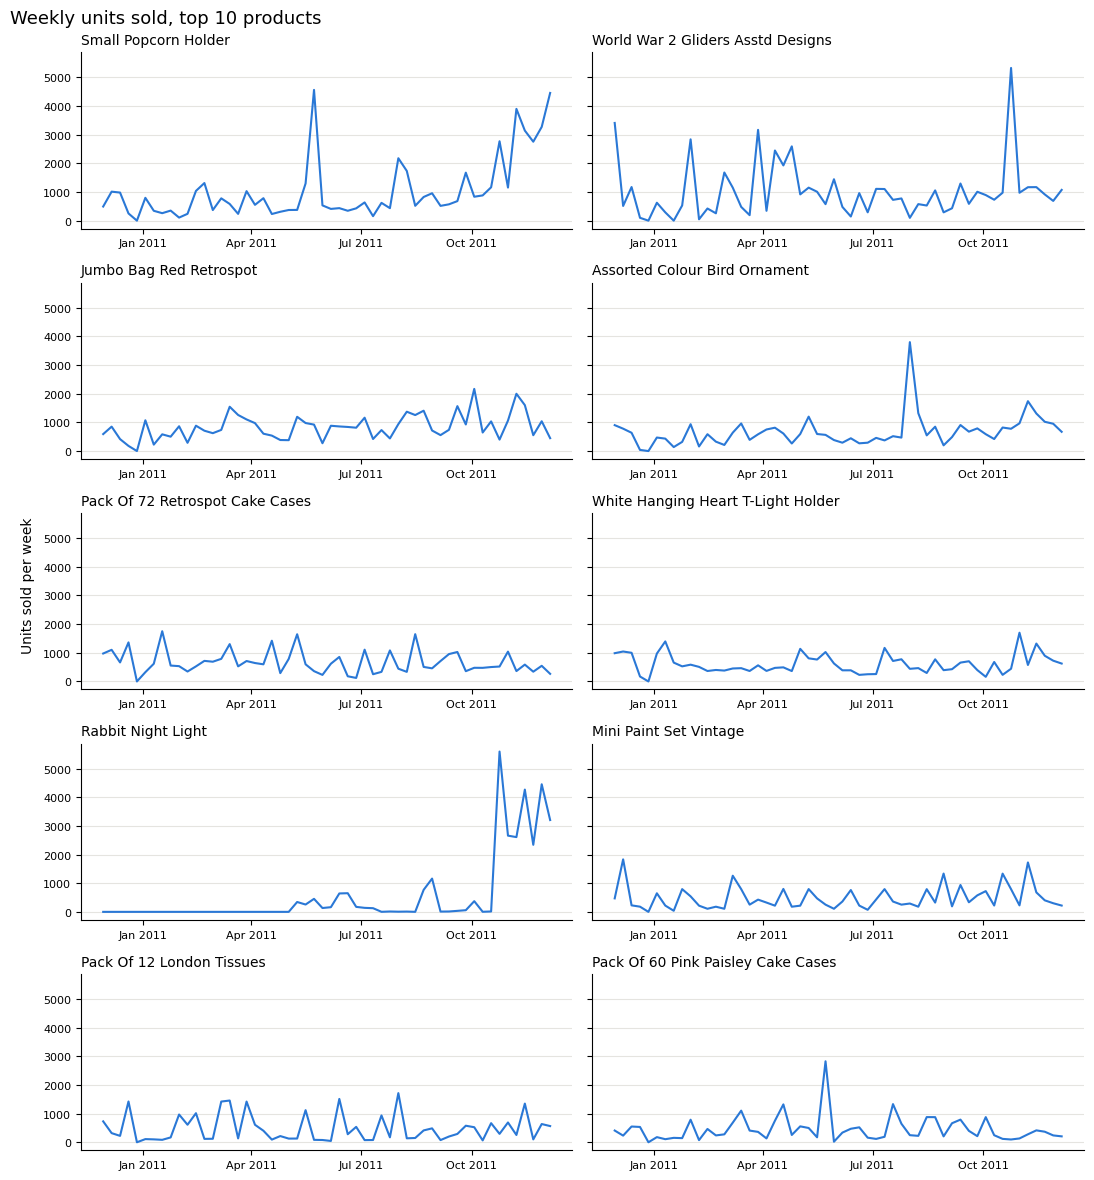

In [4]:
# Step 2: Look at the sales of each product over time.
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Largest seller first, so the panels follow the Top 10 order.
product_order = (
    weekly_sales.groupby('Description')['WeeklyQuantity']
    .sum()
    .sort_values(ascending=False)
    .index
)

# One small chart per product. They share a scale, so their heights can be compared.
fig, axes = plt.subplots(5, 2, figsize=(11, 12), sharex=True, sharey=True)

for ax, product in zip(axes.flat, product_order):
    sales = weekly_sales[weekly_sales['Description'] == product]
    ax.plot(sales['Week'], sales['WeeklyQuantity'], color='#2a78d6', linewidth=1.5)
    ax.set_title(product.title(), fontsize=10, loc='left')
    ax.grid(axis='y', color='#e5e4e0', linewidth=0.8)
    ax.spines[['top', 'right']].set_visible(False)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.tick_params(labelbottom=True, labelsize=8)

fig.suptitle('Weekly units sold, top 10 products', fontsize=13, x=0.01, ha='left')
fig.supylabel('Units sold per week', fontsize=10)
fig.tight_layout()
plt.show()


In [5]:
# Step 3: Remove the incomplete weeks, then hide the last 8 full weeks.

# The first week is missing Monday and Tuesday. The last week is missing Friday afternoon and Sunday.
FIRST_FULL_WEEK = pd.Timestamp('2010-12-06')
LAST_FULL_WEEK = pd.Timestamp('2011-11-28')

full_weeks = weekly_sales[weekly_sales['Week'].between(FIRST_FULL_WEEK, LAST_FULL_WEEK)].copy()

# Split by date, never at random: the model may only learn from the past.
TEST_WEEKS = 8
all_weeks = sorted(full_weeks['Week'].unique())
test_start = all_weeks[-TEST_WEEKS]

train = full_weeks[full_weeks['Week'] < test_start]
test = full_weeks[full_weeks['Week'] >= test_start]

print('Full weeks:', len(all_weeks))
print(f"Training: {train['Week'].nunique()} weeks, {train['Week'].min().date()} to {train['Week'].max().date()}, {len(train)} rows")
print(f"Hidden:   {test['Week'].nunique()} weeks, {test['Week'].min().date()} to {test['Week'].max().date()}, {len(test)} rows")
print('Average units per product per week, training:', round(train['WeeklyQuantity'].mean()))
print('Average units per product per week, hidden:', round(test['WeeklyQuantity'].mean()))


Full weeks: 52
Training: 44 weeks, 2010-12-06 to 2011-10-03, 440 rows
Hidden:   8 weeks, 2011-10-10 to 2011-11-28, 80 rows
Average units per product per week, training: 585
Average units per product per week, hidden: 1148


In [6]:
# Step 4: The baseline. Next week's sales = the average of the 4 weeks before it.
import numpy as np

# shift(1) moves sales down one week, so a week can never use its own sales.
full_weeks['baseline_forecast'] = full_weeks.groupby('StockCode')['WeeklyQuantity'].transform(
    lambda sales: sales.shift(1).rolling(4).mean()
)

results = full_weeks[full_weeks['Week'] >= test_start].copy()
results['error'] = results['WeeklyQuantity'] - results['baseline_forecast']

baseline_mae = results['error'].abs().mean()
baseline_rmse = np.sqrt((results['error'] ** 2).mean())
print(f'Baseline MAE:  {baseline_mae:.1f} units')
print(f'Baseline RMSE: {baseline_rmse:.1f} units')

# The same two scores for each product, worst first.
results.groupby('Description')['error'].agg(
    MAE=lambda error: error.abs().mean(),
    RMSE=lambda error: np.sqrt((error ** 2).mean()),
).round(1).sort_values('MAE', ascending=False)


Baseline MAE:  593.9 units
Baseline RMSE: 1028.2 units


,MAE,RMSE
Description,,
RABBIT NIGHT LIGHT,1484.6,2190.4
WORLD WAR 2 GLIDERS ASSTD DESIGNS,1151.1,1730.3
SMALL POPCORN HOLDER,742.9,1097.4
JUMBO BAG RED RETROSPOT,557.5,660.5
MINI PAINT SET VINTAGE,530.3,605.4
WHITE HANGING HEART T-LIGHT HOLDER,392.2,548.5
PACK OF 12 LONDON TISSUES,341.8,420.4
ASSORTED COLOUR BIRD ORNAMENT,334.1,422.1
PACK OF 60 PINK PAISLEY CAKE CASES,211.5,229.6


In [7]:
# Step 5: Build the clues the model will learn from.

# Rabbit Night Light was not on sale before May 2011, so those zeros are not real demand.
# Keep each product's weeks only from its first sale onwards.
has_sold = full_weeks.groupby('StockCode')['WeeklyQuantity'].transform(lambda sales: (sales > 0).cummax())
model_data = full_weeks[has_sold].copy()
print('Rows removed before a first sale:', len(full_weeks) - len(model_data))

# Every clue is shifted first, so it only uses weeks before the one being predicted.
by_product = model_data.groupby('StockCode')['WeeklyQuantity']
model_data['sales_last_week'] = by_product.shift(1)
model_data['sales_2_weeks_ago'] = by_product.shift(2)
model_data['average_last_4_weeks'] = by_product.transform(lambda sales: sales.shift(1).rolling(4).mean())

# A product's first 4 weeks have no full 4-week history, so they cannot be used.
CLUES = ['sales_last_week', 'sales_2_weeks_ago', 'average_last_4_weeks']
model_data = model_data.dropna(subset=CLUES)

train_rows = model_data[model_data['Week'] < test_start]
test_rows = model_data[model_data['Week'] >= test_start]

print(f"Training rows: {len(train_rows)}, weeks {train_rows['Week'].min().date()} to {train_rows['Week'].max().date()}")
print(f"Hidden rows:   {len(test_rows)}, weeks {test_rows['Week'].min().date()} to {test_rows['Week'].max().date()}")

# Check one row by hand: Small Popcorn Holder, week of 10 Oct 2011.
test_rows[(test_rows['StockCode'] == '22197') & (test_rows['Week'] == '2011-10-10')][
    ['Week', 'WeeklyQuantity'] + CLUES
]


Rows removed before a first sale: 22
Training rows: 378, weeks 2011-01-03 to 2011-10-03
Hidden rows:   80, weeks 2011-10-10 to 2011-11-28


,Week,WeeklyQuantity,sales_last_week,sales_2_weeks_ago,average_last_4_weeks
153,2011-10-10,881,835.0,1675.0,940.5


In [8]:
# Step 6: Train the random forest and compare it with the baseline on the hidden weeks.
from sklearn.ensemble import RandomForestRegressor

# random_state fixes the randomness, so everyone who re-runs this gets the same result.
model = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42)
model.fit(train_rows[CLUES], train_rows['WeeklyQuantity'])

test_rows = test_rows.copy()
test_rows['model_forecast'] = model.predict(test_rows[CLUES])

def score(forecast_column):
    error = test_rows['WeeklyQuantity'] - test_rows[forecast_column]
    return {'MAE': error.abs().mean(), 'RMSE': np.sqrt((error ** 2).mean())}

pd.DataFrame({
    'Baseline': score('baseline_forecast'),
    'Random forest': score('model_forecast'),
}).round(1).T


,MAE,RMSE
Baseline,593.9,1028.2
Random forest,708.1,1201.5


In [9]:
# Step 7: Forecast the next 4 weeks for each product.

# Now that testing is done, the model can learn from every full week we have.
final_model = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42)
final_model.fit(model_data[CLUES], model_data['WeeklyQuantity'])

future_weeks = pd.date_range(LAST_FULL_WEEK + pd.Timedelta(weeks=1), periods=4, freq='7D')
future_rows = []

for (stock_code, description), product in full_weeks.groupby(['StockCode', 'Description']):
    recent_sales = product['WeeklyQuantity'].tail(4).tolist()

    # Baseline: the average of the last 4 real weeks, used for all 4 future weeks.
    baseline = sum(recent_sales) / 4

    # Model: each future week uses the model's own guess as "last week's sales".
    for week in future_weeks:
        clues = pd.DataFrame(
            [[recent_sales[-1], recent_sales[-2], sum(recent_sales[-4:]) / 4]],
            columns=CLUES,
        )
        model_guess = final_model.predict(clues)[0]
        recent_sales.append(model_guess)
        future_rows.append({
            'Week': week,
            'StockCode': stock_code,
            'Description': description,
            'baseline_forecast': baseline,
            'model_forecast': model_guess,
        })

future = pd.DataFrame(future_rows)

# The shop made no sales from 24 Dec 2010 to 3 Jan 2011, so we assume it closes again.
CLOSED_WEEK = pd.Timestamp('2011-12-26')
future.loc[future['Week'] == CLOSED_WEEK, ['baseline_forecast', 'model_forecast']] = 0

# Baseline forecast for each product, because the baseline won the test.
future.pivot(index='Description', columns='Week', values='baseline_forecast').round(0)


Week,2011-12-05,2011-12-12,2011-12-19,2011-12-26
Description,,,,
ASSORTED COLOUR BIRD ORNAMENT,1256.0,1256.0,1256.0,0.0
JUMBO BAG RED RETROSPOT,1298.0,1298.0,1298.0,0.0
MINI PAINT SET VINTAGE,776.0,776.0,776.0,0.0
PACK OF 12 LONDON TISSUES,585.0,585.0,585.0,0.0
PACK OF 60 PINK PAISLEY CAKE CASES,325.0,325.0,325.0,0.0
PACK OF 72 RETROSPOT CAKE CASES,459.0,459.0,459.0,0.0
RABBIT NIGHT LIGHT,3416.0,3416.0,3416.0,0.0
SMALL POPCORN HOLDER,3267.0,3267.0,3267.0,0.0
WHITE HANGING HEART T-LIGHT HOLDER,880.0,880.0,880.0,0.0


In [10]:
# Step 8: Save the results for the dashboard and the restock step.

# The hidden weeks have real sales to compare with. The future weeks do not, so 'actual' is blank.
hidden_part = test_rows.rename(columns={'WeeklyQuantity': 'actual'})
future_part = future.assign(actual=np.nan)

forecasts = pd.concat([hidden_part, future_part], ignore_index=True).rename(columns={'Week': 'week_start'})
forecasts = forecasts[['week_start', 'StockCode', 'actual', 'baseline_forecast', 'model_forecast']]
forecasts = forecasts.sort_values(['StockCode', 'week_start']).round(
    {'actual': 1, 'baseline_forecast': 1, 'model_forecast': 1}
)

forecasts_path = f'{DRIVE_ROOT}/outputs/forecasts.csv'
forecasts.to_csv(forecasts_path, index=False)

# Read the saved file back, to check what was actually written.
saved = pd.read_csv(forecasts_path)
print('Saved to:', forecasts_path)
print('Rows:', len(saved))
print('Rows with real sales:', saved['actual'].notna().sum())
print('Future rows (actual is blank):', saved['actual'].isna().sum())
print('Missing forecasts:', saved[['baseline_forecast', 'model_forecast']].isna().sum().sum())
saved.head()


Saved to: /content/drive/MyDrive/WTM-Data-Science-Group-B/outputs/forecasts.csv
Rows: 120
Rows with real sales: 80
Future rows (actual is blank): 40
Missing forecasts: 0


,week_start,StockCode,actual,baseline_forecast,model_forecast
0,2011-10-10,21212,475.0,704.8,590.7
1,2011-10-17,21212,503.0,584.8,786.3
2,2011-10-24,21212,521.0,453.5,1008.4
3,2011-10-31,21212,1041.0,494.0,763.0
4,2011-11-07,21212,362.0,635.0,655.8


In [11]:
# Step 9: Turn the forecast into a restock recommendation.

# The dataset has no stock or delivery data. The team agreed these three assumptions.
DELIVERY_WEEKS = 2     # an order takes 2 weeks to arrive
BUFFER_WEEKS = 1       # spare stock: 1 extra week of forecast sales
STOCK_WEEKS = 4        # starting stock: 4 weeks of the product's usual sales

# The decision is made at the start of the week of 5 Dec 2011, using the baseline forecast.
restock = future[future['Week'] == future_weeks[0]][['StockCode', 'Description', 'baseline_forecast']].copy()
restock = restock.rename(columns={'baseline_forecast': 'weekly_forecast'})

# Usual sales: the average week from the product's first sale, before the 4 weeks behind the forecast.
before_recent_weeks = full_weeks[has_sold & (full_weeks['Week'] < all_weeks[-4])]
usual_sales = before_recent_weeks.groupby('StockCode')['WeeklyQuantity'].mean()
restock['usual_weekly_sales'] = restock['StockCode'].map(usual_sales)

restock['reorder_point'] = restock['weekly_forecast'] * (DELIVERY_WEEKS + BUFFER_WEEKS)
restock['assumed_stock'] = restock['usual_weekly_sales'] * STOCK_WEEKS
restock = restock.round({'weekly_forecast': 0, 'usual_weekly_sales': 0, 'reorder_point': 0, 'assumed_stock': 0})

restock['reorder'] = (restock['assumed_stock'] < restock['reorder_point']).map({True: 'Yes', False: 'No'})
restock['order_at_least'] = (restock['reorder_point'] - restock['assumed_stock']).clip(lower=0)
restock = restock.sort_values('order_at_least', ascending=False)

restock_path = f'{DRIVE_ROOT}/outputs/restock.csv'
restock.to_csv(restock_path, index=False)
print('Saved to:', restock_path)
print('Products to reorder:', (restock['reorder'] == 'Yes').sum(), 'of', len(restock))

restock[['Description', 'weekly_forecast', 'reorder_point', 'assumed_stock', 'reorder', 'order_at_least']]


Saved to: /content/drive/MyDrive/WTM-Data-Science-Group-B/outputs/restock.csv
Products to reorder: 6 of 10


,Description,weekly_forecast,reorder_point,assumed_stock,reorder,order_at_least
20,RABBIT NIGHT LIGHT,3416.0,10249.0,2124.0,Yes,8125.0
8,SMALL POPCORN HOLDER,3267.0,9801.0,3220.0,Yes,6581.0
28,ASSORTED COLOUR BIRD ORNAMENT,1256.0,3768.0,2475.0,Yes,1293.0
32,JUMBO BAG RED RETROSPOT,1298.0,3896.0,3255.0,Yes,641.0
12,MINI PAINT SET VINTAGE,776.0,2330.0,1891.0,Yes,439.0
36,WHITE HANGING HEART T-LIGHT HOLDER,880.0,2639.0,2323.0,Yes,316.0
4,PACK OF 60 PINK PAISLEY CAKE CASES,325.0,975.0,1881.0,No,0.0
0,PACK OF 72 RETROSPOT CAKE CASES,459.0,1378.0,2760.0,No,0.0
16,PACK OF 12 LONDON TISSUES,585.0,1754.0,1873.0,No,0.0
24,WORLD WAR 2 GLIDERS ASSTD DESIGNS,985.0,2956.0,3853.0,No,0.0


## Restock recommendation

**Assumptions agreed by the team:** the dataset has no stock or delivery data, so these numbers are assumed, not measured.
- **Delivery time:** 2 weeks.
- **Safety buffer:** 1 extra week of forecast sales.
- **Starting stock:** 4 weeks of each product's usual sales, as if the shop bought for a normal month before the busy season.

**Sum:** reorder point = weekly forecast × delivery time + safety buffer. If assumed stock is below the reorder point, reorder.

**Result:** reorder 6 of the 10 products. Rabbit Night Light (at least 8,125) and Small Popcorn Holder (at least 6,581) are the largest orders.

**How firm this is:** across 9 combinations of assumptions, Rabbit Night Light and Small Popcorn Holder always needed reordering, Assorted Colour Bird Ornament needed it in 8, and both Cake Cases products never did. The other five depend more on the assumptions.

**Caution:** an order placed on 5 Dec would arrive around 19 Dec, just before the likely Christmas closure, and sales fell at that time last year. These numbers are a starting point, and the shop owner makes the final decision.


## Results and limitations

**Result:** on the 8 hidden weeks (10 Oct to 28 Nov 2011), the simple baseline beat the random forest, so we use the baseline for the restock recommendations.

| Method | MAE (units) | RMSE (units) |
|---|---|---|
| Baseline: average of the last 4 weeks | 593.9 | 1028.2 |
| Random forest | 708.1 | 1201.5 |

**Why the baseline won:** the hidden weeks averaged about twice the sales of the training weeks. The random forest's highest forecast was 1,314 units, while actual sales reached 5,593. The baseline rises as recent sales rise.

**Decisions we made:**
- Removed the first and last weeks, because they are incomplete.
- Removed Rabbit Night Light's weeks before its first sale (10 May 2011), because it was not yet on sale.
- Left out a near-Christmas clue, because no training rows fall in November or December.
- Set the week of 26 Dec 2011 to 0, because the shop made no sales from 24 Dec 2010 to 3 Jan 2011. This is an assumption based on one year.

**Limitations:**
- We have only one year of data, so the model cannot learn the yearly Christmas pattern.
- We tested forecasts one week ahead, but the final forecast goes up to 4 weeks ahead, so its real errors may be larger.
- The forecasts for 12 and 19 Dec may be too high: last year, these products' sales fell each week in the run-up to Christmas.
- Sudden one-week spikes cannot be predicted from past sales alone.
- We have no stock data, so we record sales, not true demand. A product that ran out of stock would look like it had low demand.
